# 02-12. 지수가중함수(ewm)

## ewm()
: ewm은 지수가중함수이다. 
- 오래된 데이터에 지수감쇠를 적용하여 최근 데이터가 더 큰 영향을 끼치도록 가중치를 주는 함수이다.
- 보통 추가 메서드로 `mean()`을 사용해서 지수가중평균으로 사용한다.

### 사용법
```python
df.ewm(com=None, span=None, halflife=None, alpha=None, min_periods=0, adjust=True, ignore_na=False, axis=0, times=None, method='single').추가메서드()
```
기본적으로 가중치를 결정하는 요소는 alpha로 표기되는 평활계수(감쇠계수)이다. com / span / halflife를 통해 자동 계산하도록 하거나, alpha를 통해 직접 설정할 수 있다.
- com : 질량중심 값으로 평활계수를 계산한다. [ α = 1 / (1 + com) ]
- span : 계산 기간으로 평활계수를 계산한다. [ α = 2 / (span + 1) ]
- halflife : 반감기를 이용하여 평활계수를 계산한다. [ α = 1 - exp(-ln(2) / halflife) ]
- alpha : 평활계수를 직접 입력한다. [ 0 < α ≤ 1 ]
- min_periods : 계산을 위한 최소 기간이다.
- adjust : 상대적 가중치의 불균형을 해소하기 위해 조정계수로 나눌지의 여부이다. 대체로 값이 많을수록 adjust를 하는 것이 유리하다.
- ignore_na : 가중치를 계산할 때 누락값을 무시할지 여부이다. (False이면 절대 위치를 기반으로 가중치를 계산한다.)
- axis : 계산을 수행할 축이다.
- times : 관찰에 해당하는 시간이다. 단조증가하는 datetime64[ns] 형태여야 한다.
- method : { single / table } 열별로 계산할지(기본값) 아니면 전체 DataFrame을 함께 계산할지 정한다.
    - `table`은 DataFrame에서만 사용할 수 있으며, `numba` 라이브러리와 추가 메서드의 `engine='numba'` 설정이 필요하다.

In [1]:
import numpy as np
import pandas as pd

In [2]:
# 결측값이 포함된 DataFrame 생성
data = {'val': [1, 4, 2, 3, 2, 5, 13, 10, 12, 14, np.nan, 16, 12, 20, 22]}

df = pd.DataFrame(data).reset_index()

print(df)

    index   val
0       0   1.0
1       1   4.0
2       2   2.0
3       3   3.0
4       4   2.0
5       5   5.0
6       6  13.0
7       7  10.0
8       8  12.0
9       9  14.0
10     10   NaN
11     11  16.0
12     12  12.0
13     13  20.0
14     14  22.0


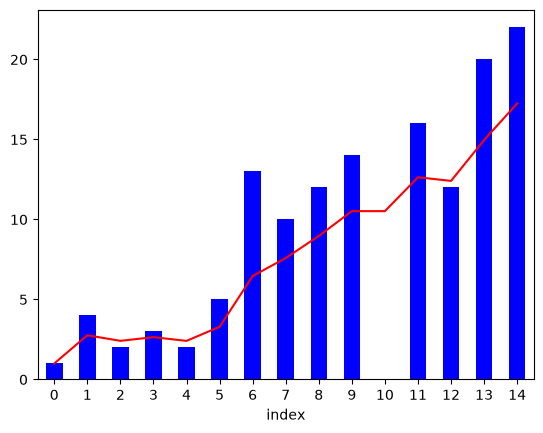

In [3]:
# 기본적인 사용법 : com / span / halflife 를 통한 평활계수의 계산 or alpha를 통한 평활계수의 직접 지정하여 지수가중평균을 계산한다.
# 붉은선(ax2)은 지수가중평균을 나타낸다.
df2 = df.assign(ewm=df['val'].ewm(alpha=0.3).mean())
ax = df.plot(kind='bar', x='index', y='val', color='blue', legend=False)
ax2 = df2.plot(kind='line', x='index', y='ewm', color='red', ax=ax, legend=False)

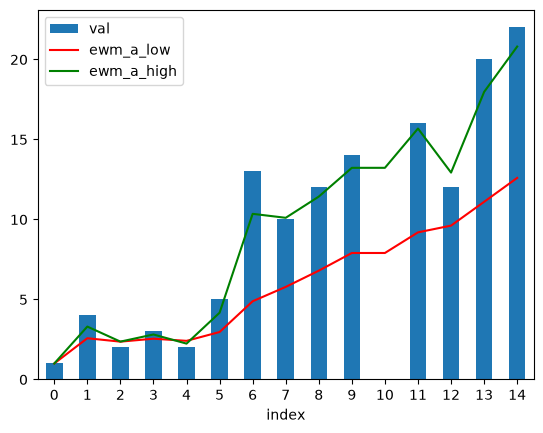

In [4]:
# alpha(평활계수) 에 따른 차이
df2 = df.assign(ewm_a_low=df['val'].ewm(alpha=0.1).mean()) #alpha=0.1로 df2 생성
df3 = df.assign(ewm_a_high=df['val'].ewm(alpha=0.7).mean()) #alpha=0.7로 df3 생성
ax = df.plot(kind='bar',x='index',y='val') 
ax2= df2.plot(kind='line',x='index', y='ewm_a_low', color='red', ax=ax) # alpha=0.1 은 적색
ax3= df3.plot(kind='line',x='index', y='ewm_a_high', color='green', ax=ax) # alpha=0.7 은 녹색

# alpha가 0.1인 적색선보다. alpha가 0.7인 녹색선이 급격한 변화에 더 민감한 것을 볼 수 있다.

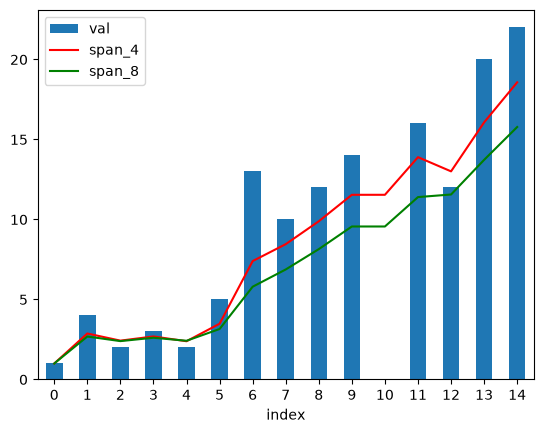

In [5]:
# span 인수의 사용
df2 = df.assign(span_4=df['val'].ewm(span=4).mean())
df3 = df.assign(span_8=df['val'].ewm(span=8).mean())
ax = df.plot(kind='bar',x='index',y='val')
ax2= df2.plot(kind='line',x='index', y='span_4', color='red', ax=ax)
ax3= df3.plot(kind='line',x='index', y='span_8', color='green', ax=ax)

# span이 긴 녹색이 span이 짧은 적색선보다 덜 민감하게 반응하는 것을 확인 할 수 있다.
# span이 길면 그만큼 과거의 데이터의 영향이 커지기 때문이다.

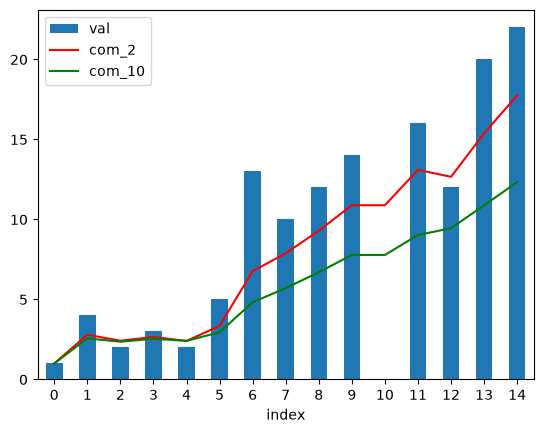

In [6]:
# com 인수의 사용(com 은 질량중심 감쇠법으로 평활계수를 계산하는 인수, 계산식은 alpha = 1/(1+com) 이다.)
# com이 커질수록 평활계수 alpha는 작아지고, alpha가 작아지면 지수가중평균은 과거의 데이터에 더 민감하게 반응한다.

df2 = df.assign(com_2=df['val'].ewm(com=2).mean())
df3 = df.assign(com_10=df['val'].ewm(com=10).mean())
ax = df.plot(kind='bar',x='index',y='val')
ax2= df2.plot(kind='line',x='index', y='com_2', color='red', ax=ax)
ax3= df3.plot(kind='line',x='index', y='com_10', color='green', ax=ax)


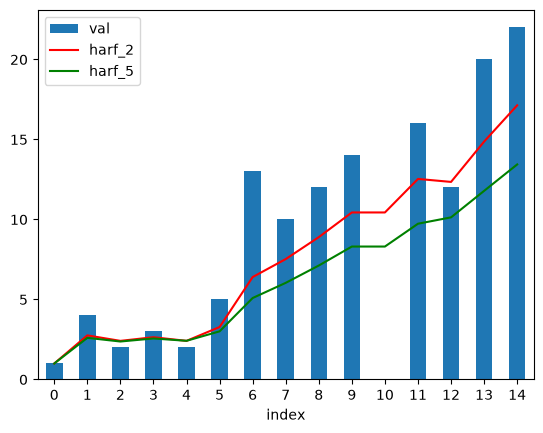

In [7]:
# halflife 인수(반감기를 이용하여 평활계수를 계산하는 인수)의 사용
# 계산식은 a=1-e^(-ln(2)/halflife) 으로 halflife가 길어질수록 a가 작아진다.
df2 = df.assign(harf_2=df['val'].ewm(halflife=2).mean())
df3 = df.assign(harf_5=df['val'].ewm(halflife=5).mean())
ax = df.plot(kind='bar',x='index',y='val')
ax2= df2.plot(kind='line',x='index', y='harf_2', color='red', ax=ax)
ax3= df3.plot(kind='line',x='index', y='harf_5', color='green', ax=ax)

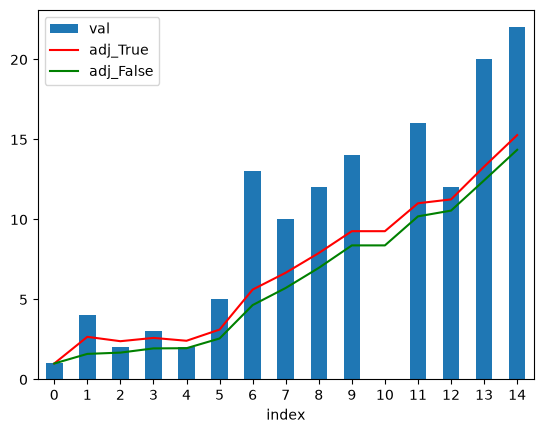

In [8]:
# adjust인수의 사용 : 상대적 가중치의 불균형을 해소하기위해 조정계수로 나눌지의 여부를 나타낸다.
# 대체로 값이 많을수록 adjust를 하는것이 유리하다.

df2 = df.assign(adj_True=df['val'].ewm(alpha=0.2,adjust=True).mean())
df3 = df.assign(adj_False=df['val'].ewm(alpha=0.2,adjust=False).mean())
ax = df.plot(kind='bar',x='index',y='val')
ax2= df2.plot(kind='line',x='index', y='adj_True', color='red', ax=ax)
ax3= df3.plot(kind='line',x='index', y='adj_False', color='green', ax=ax)


결측치가 있는 10번 data부터 ignore_na의 여부에 따라 그래프가 달라지는것을 볼 수 있다


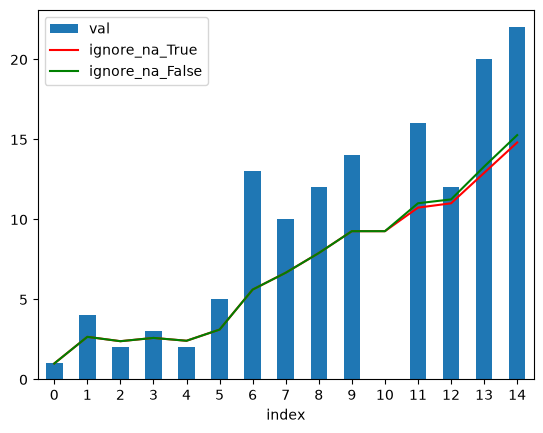

In [9]:
# ignore_na인수(결측치가 존재할 경우 가중치를 어떻게 설정할지 정하는 인수 )의 사용

df2 = df.assign(ignore_na_True=df['val'].ewm(alpha=0.2,ignore_na=True).mean())
df3 = df.assign(ignore_na_False=df['val'].ewm(alpha=0.2,ignore_na=False).mean())
ax = df.plot(kind='bar',x='index',y='val')
ax2= df2.plot(kind='line',x='index', y='ignore_na_True', color='red', ax=ax)
ax3= df3.plot(kind='line',x='index', y='ignore_na_False', color='green', ax=ax)

print("결측치가 있는 10번 data부터 ignore_na의 여부에 따라 그래프가 달라지는것을 볼 수 있다")


In [10]:
# method 인수의 사용
# method='single'은 열별로 계산하고, method='table'은 DataFrame 전체를 함께 계산한다.
# table은 Series에 사용할 수 없으므로 DataFrame 형태로 선택해야 한다.

import numba
print(df[['val']].ewm(alpha=0.2, method='table').mean(engine='numba'))


          val
0    1.000000
1    2.666667
2    2.393443
3    2.598916
4    2.420752
5    3.119872
6    5.620269
7    6.672800
8    7.903410
9    9.269400
10   9.269400
11  11.014705
12  11.255896
13  13.304608
14  15.274352
